# Support Vector Machine (SVM)

## Fundamentos Teóricos

Una Support Vector Machine (SVM), o máquina de vectores de soporte, es un algoritmo de aprendizaje automático supervisado que busca encontrar el hiperplano óptimo para separar clases. A diferencia de otros modelos que se conforman con encontrar cualquier límite funcional, SVM se basa en una optimización matemática precisa para garantizar la mejor generalización ante datos nuevos.   

* Hiperplano óptimo: El objetivo principal del algoritmo es pasar de infinitas rectas posibles a encontrar de manera exacta una única solución matemática (el hiperplano) que separe las clases.   
* Maximización del margen: Este hiperplano óptimo maximiza el margen geométrico, el cual representa la distancia total del canal de separación entre las clases y equivale a $2/\Vert{}\mathbf{w}\Vert{}$.   

* Vectores de Soporte: Son los puntos críticos de los datos de entrenamiento que se encuentran en el límite del margen y que definen de forma exclusiva la posición de la frontera. Eliminar o mover cualquier otro punto de la muestra no altera en absoluto el hiperplano óptimo.  

* Garantía de solución única: Mediante la optimización cuadrática convexa, SVM asegura que siempre encontrará el mismo e inmejorable hiperplano de separación.   

# Elementos matemáticos del modelo

* Entradas ($\mathbf{x}$): Son las características de los datos de entrada, representadas como un vector:

$$\mathbf{x} = (x_1, x_2, \ldots, x_n)$$

* Vector de Pesos ($\mathbf{w}$): Parámetro que determina la orientación de la frontera. Es un vector perpendicular al hiperplano de decisión.
La norma al cuadrado de este vector, $\Vert{}\mathbf{w}\Vert{}^2$, es lo que el modelo busca minimizar, lo cual es equivalente a maximizar la distancia del margen.   

* Sesgo ($b$): Parámetro de la ecuación del hiperplano que permite desplazar el límite de decisión sin cambiar su orientación.   

* Frontera de Decisión: Es la ecuación matemática que divide el espacio de las clases:
   
$$\mathbf{w}^T\mathbf{x} + b = 0$$

* Límites del Margen: Las ecuaciones que definen las fronteras paralelas que delimitan el margen de separación son:

$$\mathbf{w}^T\mathbf{x} + b = \pm 1$$
   
* Función de Clasificación: Para predecir a qué clase pertenece un dato nuevo, se evalúa de qué lado del hiperplano cae mediante la función signo, la cual asigna $+1$ si el resultado es positivo y $-1$ si es negativo:
   
$$f(\mathbf{x}) = \text{sign}(\mathbf{w}^T\mathbf{x} + b)$$
   
* Función de Optimización (Margen Rígido): Busca una separación perfecta sin errores al minimizar la norma de los pesos, sujeta a que todos los puntos estén correctamente clasificados fuera del margen:

$$\min \frac{1}{2} \Vert{}\mathbf{w}\Vert{}^2 \quad \text{sujeto a} \quad y_i(\mathbf{w}^T\mathbf{x}_i + b) \ge 1$$
   
* Margen Flexible (Soft Margin): Cuando los datos no son perfectamente separables, se introduce el hiperparámetro de penalización $C$ y las variables de holgura $\xi_i$ para permitir y controlar ciertas violaciones al margen:

$$\min \frac{1}{2} \Vert{}\mathbf{w}\Vert{}^2 + C \sum \xi_i \quad \text{sujeto a} \quad y_i(\mathbf{w}^T\mathbf{x}_i + b) \ge 1 - \xi_i$$

## Dimensionalidad: Clasificación en $R^2$ vs $R^N$

El comportamiento geométrico y matemático del SVM se adapta dependiendo del espacio dimensional en el que operan los datos:

* En espacio bidimensional ($R^2$): La frontera de decisión o separador lineal es geométricamente una línea recta. Si los datos están mezclados y no se pueden separar con una recta, el modelo en su forma base falla.   

* En espacio multidimensional ($R^3$ o superior): La frontera de decisión se convierte en un plano plano (en 3D) o en un hiperplano (en dimensiones superiores).   

* Técnica Kernel ("Kernel Trick"): Para resolver la limitación de los datos no lineales en $R^2$, el algoritmo utiliza el "Truco del Kernel" ($\Phi(\mathbf{x})$). Esta técnica aplica funciones matemáticas (como Radiales/RBF o Polinomiales) para proyectar o "elevar" los datos desde un espacio de baja dimensión ($R^2$) a un espacio de mayor dimensión ($R^3$ o $R^N$). En esta nueva dimensión superior, los datos sí se vuelven linealmente separables por un hiperplano, todo esto sin necesidad de calcular explícitamente las coordenadas transformadas.   

* Clasificación Multiclase: Aunque el SVM es por naturaleza un clasificador binario, en espacios $R^N$ puede resolver la separación de 3 o más clases combinando múltiples fronteras mediante estrategias matemáticas como Uno contra Todos (OvR), donde la clase con mayor puntuación de confianza gana, o Uno contra Uno (OvO), donde los submodelos votan en pares.   

# Pipeline SVM

Por motivos prácticos vamos a estudiar un escenario donde la clasificación es binaria. Además de comparar la frontera óptima del modelo SVM, con la convergencia en épocas del Perceptron.

### 1. Dataset, librerias necesarias y procesamiento de datos

La primera fase de cualquier pipeline de Machine Learning es la adquisición de la información y su adecuación geométrica o estadística.







In [1]:
# Librerias básicas
import numpy as np # arrgelos y operaciones mátematicas
import pandas as pd # Manipulación y análisis (DataFrames)
import matplotlib.pyplot as plt # Visualizar los datos (crear gráficos)

from sklearn.datasets import load_iris  # En este caso importamos un dataset clásico (desde libreria)
from sklearn.preprocessing import StandardScaler  # estandarizar lo datos --> (media y desviación está.)
from sklearn.model_selection import train_test_split # segmentación del dataset

# Librerias propias del modelo
from sklearn.svm import SVC  # el modelo
from sklearn.metrics import accuracy_score, confusion_matrix  # Calculo de las métricas (exactitud y "matriz de confusión")


# Recolección de Datos
iris_raw = load_iris()  # = 150 muestras de flores / 4 características (l/w sépalo y l/w pétalo) / 3 clases: Setosa, Versicolor y Virginica

# Creamos un DataFrame para manipular e inspeccionar la información
df = pd.DataFrame(data=iris_raw.data, columns=iris_raw.feature_names)
df['especie'] = iris_raw.target

#  Filtrado para Clasificación Binaria (Setosa: 0 y Versicolor: 1)
df_binary = df[df['especie'].isin([0, 1])].copy()

# Aislamiento de Variables de Entrada (sepal length y petal length) y Etiquetas (target)
X_raw = df_binary[['sepal length (cm)', 'petal length (cm)']].to_numpy()
y = df_binary['especie'].to_numpy()
# Setosa se codificará como 0 (o -1), Versicolor como 1 (o +1)

# Escalamiento de Características
escalador = StandardScaler()  # media y desviación estándar como referencia en el escalado
X = escalador.fit_transform(X_raw)

print("=== Datos Preprocesados con Éxito ===")
print("Forma de la matriz X (Estandarizada):", X.shape)
print("Primeros 5 registros de X (sepal y petal length):")
print(X[:5])
print("Primeras 5 etiquetas:")
print(y[:5])
print("Distribución de la variable objetivo:", np.bincount(y))

=== Datos Preprocesados con Éxito ===
Forma de la matriz X (Estandarizada): (100, 2)
Primeros 5 registros de X (sepal y petal length):
[[-0.5810659  -1.01297765]
 [-0.89430898 -1.01297765]
 [-1.20755205 -1.08231219]
 [-1.36417359 -0.94364311]
 [-0.73768744 -1.01297765]]
Primeras 5 etiquetas:
[0 0 0 0 0]
Distribución de la variable objetivo: [50 50]


#### Scatter Chart

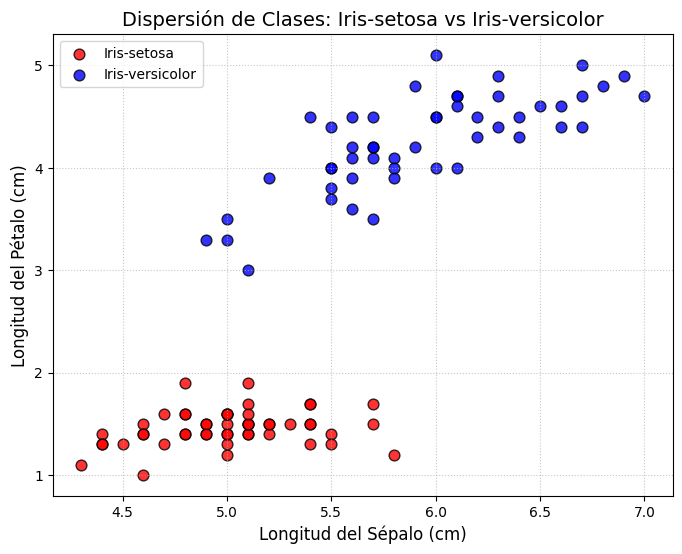

In [2]:
# Configurar y construir el Gráfico de Dispersión (Scatter Chart)
plt.figure(figsize=(8, 6))

# Graficar la clase Setosa (donde y es exactamente igual a 0)
plt.scatter(X_raw[y == 0, 0], X_raw[y == 0, 1],
            color='red', label='Iris-setosa', edgecolors='black', s=60, alpha=0.8)

# Graficar la clase Versicolor (donde y es exactamente igual a 1)
plt.scatter(X_raw[y == 1, 0], X_raw[y == 1, 1],
            color='blue', label='Iris-versicolor', edgecolors='black', s=60, alpha=0.8)

# Formato, etiquetas y leyenda
plt.title('Dispersión de Clases: Iris-setosa vs Iris-versicolor', fontsize=14)
plt.xlabel('Longitud del Sépalo (cm)', fontsize=12)
plt.ylabel('Longitud del Pétalo (cm)', fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.7)

# Mostrar la visualización
plt.show()

### 2. Selección y entrenamiento

Estas son las tareas y 'configuaración' de los modelos de clasificación que vamos a emplear.

Treas:

* Moldelo 1: SVM
  1. **División de Entrenamiento y Prueba**: Reservamos una porción de los datos (ej. 20%) para evaluar de manera imparcial el modelo.
  2. **Instanciación del Modelo**: Se utiliza el clasificador SVC (Support Vector Classifier).
  3. **Configuración del Kernel**: Pasamos kernel='linear' para asegurar su función como separador lineal puro en  R2 .
  4. **Parámetro de Penalización**: Fijamos C=10 para priorizar la búsqueda de un margen rígido o un canal lo más libre de errores posible.
  5. **Entrenamiento**: Se ejecuta el ajuste (fit) donde el algoritmo de optimización cuadrática halla el vector de pesos ( w ) y el sesgo ( b ).

In [3]:
# ----- Modelo 1 (SVM) -----
# División del dataset en conjuntos de entrenamiento (Train) y evaluación (Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Instanciación de Support Vector Machine (Clasificador lineal rígido / kernel lineal)
modelo_svm = SVC(kernel='linear', C=10.0, random_state=28) # Escogemos algoritmo que crea el tipo de frontera geometrica (kernel)

# Ajuste y aprendizaje
modelo_svm.fit(X_train, y_train)

print("=== Ajuste del Modelo Completado ===")

print(f"Vector de pesos (w) en el espacio estandarizado: {modelo_svm.coef_[0]}") # Solo hay un peso en el vector ya que se trata de una recta - una pendiente
print(f"Sesgo (b) del hiperplano: {modelo_svm.intercept_[0]:.4f}") # interseción de la recta con el eje 'y'
print(f"Cantidad de vectores de soporte identificados: {len(modelo_svm.support_vectors_)}") # datos más cercanos al espacio que dividirá la frontera.

=== Ajuste del Modelo Completado ===
Vector de pesos (w) en el espacio estandarizado: [0.         2.62233197]
Sesgo (b) del hiperplano: 0.7473
Cantidad de vectores de soporte identificados: 2


### Etapa 3: Evaluación y Scoring


Medir el desempeño del modelo sobre datos nunca antes vistos (el conjunto de prueba) para determinar su capacidad de generalización.

#### Tareas en esta sección:
1.  **Predicción**: Generar estimaciones sobre el conjunto de test.
2.  **Métricas**: Calcular el accuracy (tasa de acierto) y la matriz de confusión



#### Métricas



Presición () - ¿?

In [4]:
# Realizar predicciones sobre el subconjunto de prueba
predicciones_test = modelo_svm.predict(X_test)

# Calcular Accuracy
precision_total = accuracy_score(y_test, predicciones_test)


print(f"=== EVALUACIÓN DEL MODELO ===")
print(f"Exactitud (Accuracy): {precision_total * 100:.1f}%")

=== EVALUACIÓN DEL MODELO ===
Exactitud (Accuracy): 100.0%


Matriz de Confusión

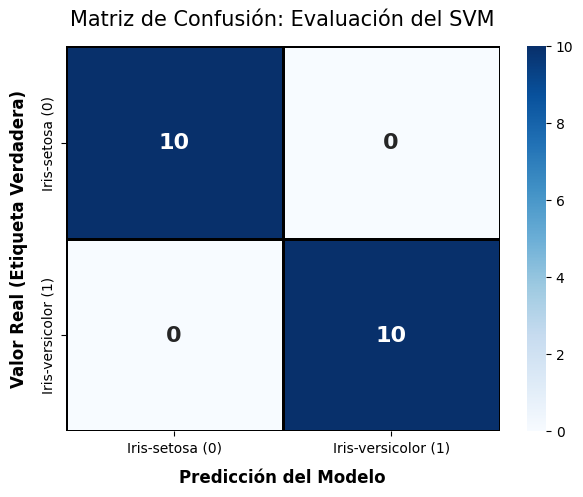

In [5]:
import seaborn as sns

# Calcular la matriz de confusión
matriz_conf = confusion_matrix(y_test, predicciones_test)

# Configurar el lienzo de la gráfica
plt.figure(figsize=(7, 5))

# Construir el mapa de calor con Seaborn
nombres_clases = ['Iris-setosa (0)', 'Iris-versicolor (1)'] # nombres de clases

sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues',          # mapa de calor
            xticklabels=nombres_clases, yticklabels=nombres_clases,  # nombrar en ejes (x, y) las clases
            cbar=True, annot_kws={"size": 16, "weight": "bold"},     # Color y formato
            linewidths=1, linecolor='black')

# Formato didáctico de las etiquetas
plt.title('Matriz de Confusión: Evaluación del SVM', fontsize=15, pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Valor Real (Etiqueta Verdadera)', fontsize=12, fontweight='bold', labelpad=10)

# Desplegar la gráfica
plt.show()

## Etapa 4: Visualización del Hiperplano Óptimo
Para el entendimiento didáctico, se grafican las observaciones originales estandarizadas junto con el **Hiperplano de Separación** y las fronteras de los márgenes soportados por los vectores críticos del modelo.

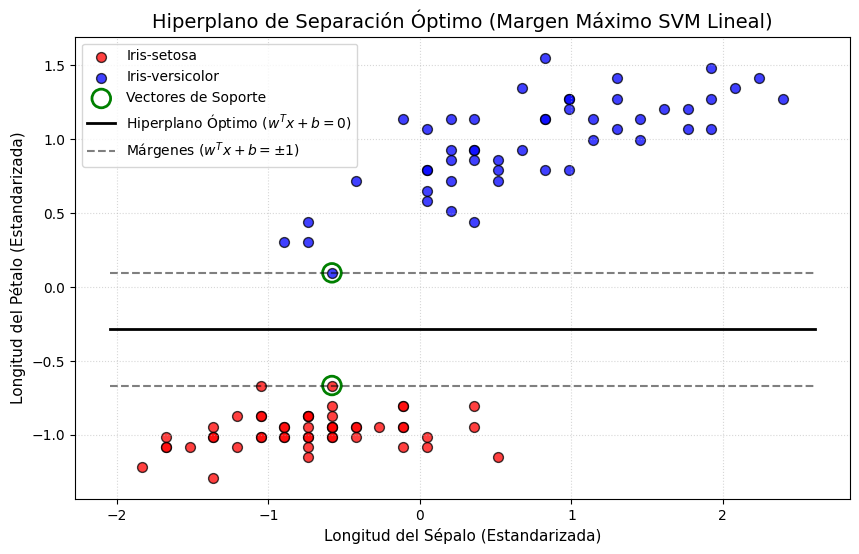

In [6]:
# ----- Modelo de SVM -------
plt.figure(figsize=(10, 6))

# Graficar los datos de entrenamiento
colores_map = {0: 'red', 1: 'blue'}
clases_map = {0: 'Iris-setosa', 1: 'Iris-versicolor'}

for val, col in colores_map.items():
    indices = (y == val)
    plt.scatter(X[indices, 0], X[indices, 1], c=col, label=clases_map[val], s=50, edgecolors='k', alpha=0.75)

# Resaltar los vectores de soporte del modelo
vectores_sop = modelo_svm.support_vectors_
plt.scatter(vectores_sop[:, 0], vectores_sop[:, 1], s=180, facecolors='none', edgecolors='green',
            linewidths=2, label='Vectores de Soporte')

# Dibujar el hiperplano óptimo y los márgenes
ax = plt.gca()
x_lim = ax.get_xlim()
x_puntos = np.linspace(x_lim[0], x_lim[1], 100)

# Coeficientes obtenidos: w[0]*x1 + w[1]*x2 + b = 0
w = modelo_svm.coef_[0]
b = modelo_svm.intercept_[0]

y_hiperplano = (-w[0] * x_puntos - b) / w[1]
y_margen_sup = (-w[0] * x_puntos - b + 1) / w[1]
y_margen_inf = (-w[0] * x_puntos - b - 1) / w[1]

# Trazar en el lienzo (SOLUCIÓN AL WARNING: Uso de 'r' para strings con LaTeX)
plt.plot(x_puntos, y_hiperplano, 'k-', linewidth=2, label=r'Hiperplano Óptimo ($w^T x + b = 0$)')
plt.plot(x_puntos, y_margen_sup, 'k--', alpha=0.5, label=r'Márgenes ($w^T x + b = \pm 1$)')
plt.plot(x_puntos, y_margen_inf, 'k--', alpha=0.5)

plt.title("Hiperplano de Separación Óptimo (Margen Máximo SVM Lineal)", fontsize=14)
plt.xlabel("Longitud del Sépalo (Estandarizada)", fontsize=11)
plt.ylabel("Longitud del Pétalo (Estandarizada)", fontsize=11)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.5)
plt.ylim(ax.get_ylim())

plt.show()

## Etapa 5: Inferencia (Predicción) sobre Nuevas Observaciones

Por último, construimos una función robusta para que el usuario o sistema externo pueda ingresar valores crudos (en centímetros) y el modelo preprocese en tiempo real el dato para poder emitir una clasificación.

In [7]:
# Definir los nuevos valores a predecir: [Longitud Sépalo, Longitud Pétalo]
nuevas_muestras = np.array([
    [5.2, 2.4], # Esperamos Iris-setosa
    [7.5, 5.8]  # Esperamos Iris-versicolor
])

# Escalar los datos y predecir directamente
predicciones = modelo_svm.predict(escalador.transform(nuevas_muestras))

# Mostrar los resultados de forma directa
etiquetas = {0: "Iris-setosa", 1: "Iris-versicolor"}

print("=== PREDICCIONES DEL MODELO ===")
for muestra, pred in zip(nuevas_muestras, predicciones):
    print(f"Medidas {muestra} cm  -->  {etiquetas[pred]}")

=== PREDICCIONES DEL MODELO ===
Medidas [5.2 2.4] cm  -->  Iris-setosa
Medidas [7.5 5.8] cm  -->  Iris-versicolor


## SVM vs Perpectron

Comparamos estos primeros métodos de clasificación, support vector machine y perceptron.

Caso del perceptron con el dataset, pero sin "tanto detalle explicado" o código innecesario; ya que, una parte se reutiliza del modelo SVM antes implementado.

### 1. Librerias y dataset

In [8]:
from sklearn.linear_model import Perceptron # la libreria del modelo

### 2. Selección y entrenamiento del modelo

In [9]:
# Instanciación del modelo Perceptrón con hiperparámetros similares al caso de SVM
modelo_per = Perceptron(
    max_iter=1000,    # Máximo número de épocas
    eta0=0.1,         # Tasa de aprendizaje (o velocidad de aprendizaje)
    random_state=42,  # Semilla para reproducibilidad
    n_jobs=-1         # Uso de todos los núcleos
)

# Ajuste y aprendizaje (usando X_train y y_train procesados en el SVM)
modelo_per.fit(X_train, y_train)

print("=== Ajuste del Modelo Perceptrón Completado ===")
print(f"El modelo convergió en {modelo_per.n_iter_} épocas.\n")


=== Ajuste del Modelo Perceptrón Completado ===
El modelo convergió en 6 épocas.



### 3. Evaluación y Scoring (métricas)

=== EVALUACIÓN DEL MODELO PERCEPTRÓN ===
Exactitud (Accuracy): 100.0%

Matriz de Confusión sin (Perceptrón):


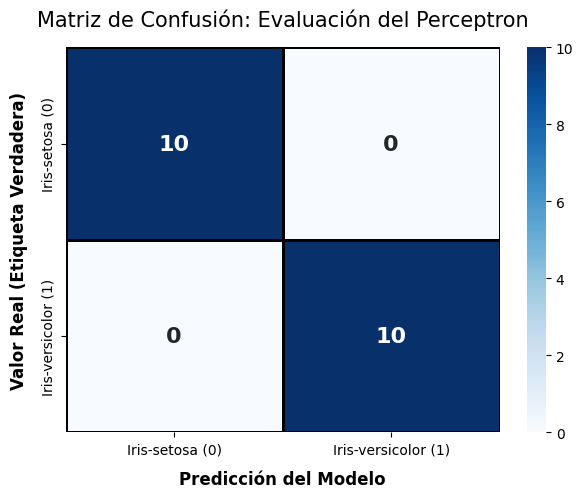

In [10]:

predicciones_per_test_percept = modelo_per.predict(X_test) # Para contrastar los "x_predecidos" con y_test "originales" (o sea propios del dataset)

# Calcular Accuracy
precision_per_total = accuracy_score(y_test, predicciones_per_test_percept)

print("=== EVALUACIÓN DEL MODELO PERCEPTRÓN ===")
print(f"Exactitud (Accuracy): {precision_per_total * 100:.1f}%\n")

# Calcular y mostrar la matriz de confusión
matriz_conf_per = confusion_matrix(y_test, predicciones_per_test_percept)


print("Matriz de Confusión sin (Perceptrón):")

plt.figure(figsize=(7, 5)) # lienzo de la gráfica

# Construir el mapa de calor con Seaborn
nombres_clases = ['Iris-setosa (0)', 'Iris-versicolor (1)'] # nombres de clases

sns.heatmap(matriz_conf_per, annot=True, fmt='d', cmap='Blues',          # mapa de calor
            xticklabels=nombres_clases, yticklabels=nombres_clases,  # nombrar en ejes (x, y) las clases
            cbar=True, annot_kws={"size": 16, "weight": "bold"},     # Color y formato
            linewidths=1, linecolor='black')

# Formato didáctico de las etiquetas
plt.title('Matriz de Confusión: Evaluación del Perceptron', fontsize=15, pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Valor Real (Etiqueta Verdadera)', fontsize=12, fontweight='bold', labelpad=10)

# Desplegar la gráfica
plt.show()

### 4. Visualización del Hiperplano Óptimo

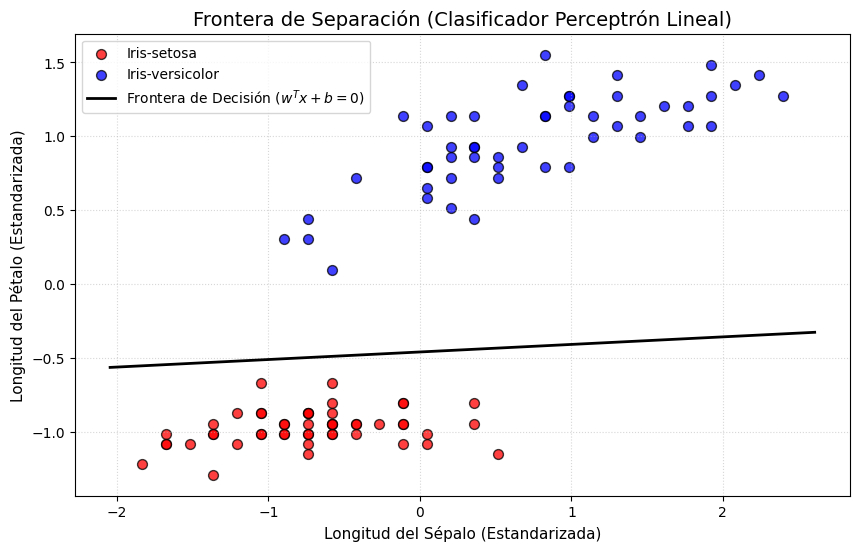

In [11]:
plt.figure(figsize=(10, 6))

# Graficar los datos de entrenamiento
colores_map = {0: 'red', 1: 'blue'}
clases_map = {0: 'Iris-setosa', 1: 'Iris-versicolor'}

for val, col in colores_map.items():
    indices = (y == val)
    plt.scatter(X[indices, 0], X[indices, 1], c=col, label=clases_map[val], s=50, edgecolors='k', alpha=0.75)

# Obtener los ejes actuales para los límites
ax = plt.gca()
x_lim = ax.get_xlim()
x_puntos = np.linspace(x_lim[0], x_lim[1], 100)

# Coeficientes obtenidos por el Perceptrón: w[0]*x1 + w[1]*x2 + b = 0
# (Asegúrate de que la variable de tu modelo perceptrón se llame 'modelo_per')
w = modelo_per.coef_[0]
b = modelo_per.intercept_[0]

# Despejando x2 (el eje Y de la gráfica) para la frontera de decisión
y_hiperplano = (-w[0] * x_puntos - b) / w[1]

# Trazar la frontera de decisión en el lienzo
plt.plot(x_puntos, y_hiperplano, 'k-', linewidth=2, label=r'Frontera de Decisión ($w^T x + b = 0$)')

# Formato y etiquetas
plt.title("Frontera de Separación (Clasificador Perceptrón Lineal)", fontsize=14)
plt.xlabel("Longitud del Sépalo (Estandarizada)", fontsize=11)
plt.ylabel("Longitud del Pétalo (Estandarizada)", fontsize=11)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.5)
plt.ylim(ax.get_ylim()) # Mantener los límites del eje Y proporcionales a los puntos

plt.show()